In [1]:
# ============================================
# RETAILPULSE - LSTM & ENSEMBLE FORECASTING
# ============================================

import pandas as pd
import numpy as np
import os
import warnings
import json
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

# PyTorch (Deep Learning)
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

# Detect if GPU is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ PyTorch version: {torch.__version__}")
print(f"💻 Device selected: {device}")

# ============================================
# BULLETPROOF PATHS
# ============================================
current_dir = os.getcwd()
if os.path.basename(current_dir) == "notebooks":
    project_root = os.path.abspath(os.path.join(current_dir, ".."))
else:
    project_root = os.path.abspath(current_dir)

processed_dir = os.path.join(project_root, "data", "processed")
figures_dir = os.path.join(project_root, "reports", "figures")
os.makedirs(figures_dir, exist_ok=True)

# ============================================
# LOAD DATA
# ============================================
ts_path = os.path.join(processed_dir, "daily_timeseries_features.parquet")
df = pd.read_parquet(ts_path)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

print(f"✅ Loaded {len(df)} days of daily sales data.")

✅ PyTorch version: 2.1.2+cpu
💻 Device selected: cpu
✅ Loaded 574 days of daily sales data.


In [2]:
# ============================================
# PREPARE LSTM SEQUENCE DATA
# ============================================

# We will forecast Daily_Revenue
data = df['Daily_Revenue'].values.reshape(-1, 1)

# Scale data to [0, 1] range (crucial for neural networks!)
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# Sliding Window Configuration
LOOKBACK = 14  # Use past 14 days to predict tomorrow
TEST_DAYS = 60 # Keep last 60 days for testing (matches Step 7)

def create_sequences(data, lookback):
    X, y = [], []
    for i in range(len(data) - lookback):
        X.append(data[i:(i + lookback)])
        y.append(data[i + lookback])
    return np.array(X), np.array(y)

# Create sequence inputs
X, y = create_sequences(scaled_data, LOOKBACK)

print(f"📊 Original dataset size: {len(df)} days")
print(f"📊 Formatted sequence dataset size: {X.shape[0]} windows")
print(f"   Each window has shape: {X.shape[1:]} (Lookback Days, Features)")
print()

# Train/Test Split (Preserving chronological order)
X_train, X_test = X[:-TEST_DAYS], X[-TEST_DAYS:]
y_train, y_test = y[:-TEST_DAYS], y[-TEST_DAYS:]

print(f"   📈 X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"   📈 X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")

📊 Original dataset size: 574 days
📊 Formatted sequence dataset size: 560 windows
   Each window has shape: (14, 1) (Lookback Days, Features)

   📈 X_train shape: (500, 14, 1) | y_train shape: (500, 1)
   📈 X_test shape:  (60, 14, 1)  | y_test shape:  (60, 1)


In [3]:
# ============================================
# PYTORCH DATASET & LSTM DEFINITION
# ============================================

# Convert NumPy arrays to PyTorch Tensors
class SalesDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Create DataLoader objects
batch_size = 16
train_dataset = SalesDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# Build the LSTM Architecture
class SalesLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2, output_size=1):
        super(SalesLSTM, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        # LSTM layer
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.2)
        
        # Fully connected output layer
        self.fc = nn.Linear(hidden_size, output_size)
        
    def forward(self, x):
        # Initialize hidden state and cell state
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
        
        # Forward propagate LSTM
        out, _ = self.lstm(x, (h0, c0))
        
        # Decode the hidden state of the last time step
        out = self.fc(out[:, -1, :])
        return out

# Instantiate model
model = SalesLSTM().to(device)
print(model)

SalesLSTM(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


⏳ Training LSTM Deep Learning Model...
   Epoch [ 1/60] → Loss: 0.039098
   Epoch [10/60] → Loss: 0.013924
   Epoch [20/60] → Loss: 0.013239
   Epoch [30/60] → Loss: 0.013127
   Epoch [40/60] → Loss: 0.014034
   Epoch [50/60] → Loss: 0.012937
   Epoch [60/60] → Loss: 0.012724

✅ LSTM training complete!


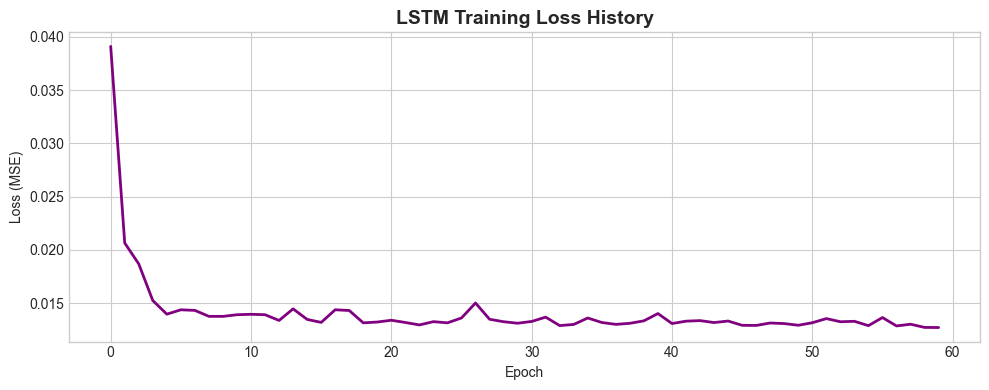

In [4]:
# ============================================
# LSTM TRAINING LOOP
# ============================================

# Loss function and Optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 60
loss_history = []

print("⏳ Training LSTM Deep Learning Model...")
print("=" * 60)

model.train()
for epoch in range(1, epochs + 1):
    epoch_loss = 0
    for batch_X, batch_y in train_loader:
        # Move tensors to selected device (CPU or GPU)
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        
        # Zero the gradients
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        
        # Backward pass and optimize
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item() * batch_X.size(0)
        
    avg_loss = epoch_loss / len(train_loader.dataset)
    loss_history.append(avg_loss)
    
    if epoch % 10 == 0 or epoch == 1:
        print(f"   Epoch [{epoch:2d}/{epochs}] → Loss: {avg_loss:.6f}")

print("\n✅ LSTM training complete!")

# Plot Training Loss
plt.figure(figsize=(10, 4))
plt.plot(loss_history, color='purple', linewidth=2)
plt.title('LSTM Training Loss History', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.tight_layout()
plt.show()

In [5]:
# ============================================
# EVALUATE LSTM PREDICTIONS
# ============================================

model.eval()
with torch.no_grad():
    # Convert test inputs to PyTorch tensors
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
    lstm_scaled_preds = model(X_test_tensor).cpu().numpy()

# Inverse transform predictions back to actual currency (£) value
lstm_preds = scaler.inverse_transform(lstm_scaled_preds).flatten()
actual_sales = df['Daily_Revenue'].values[-TEST_DAYS:]

# Calculate metrics for LSTM alone
lstm_mae = mean_absolute_error(actual_sales, lstm_preds)
lstm_rmse = np.sqrt(mean_squared_error(actual_sales, lstm_preds))
lstm_mape = np.mean(np.abs((actual_sales - lstm_preds) / actual_sales)) * 100

print("📊 LSTM MODEL PERFORMANCE (TEST SET):")
print("-" * 50)
print(f"   MAE:  £{lstm_mae:,.2f}")
print(f"   RMSE: £{lstm_rmse:,.2f}")
print(f"   MAPE: {lstm_mape:.2f}%")

📊 LSTM MODEL PERFORMANCE (TEST SET):
--------------------------------------------------
   MAE:  £7,979.64
   RMSE: £10,325.31
   MAPE: 30.07%


In [7]:
# ============================================
# CALCULATE ENSEMBLE FORECAST (FIXED & DATE-ALIGNED)
# ============================================

print("🔗 Loading Step 7 (Ridge/Prophet Fallback) results...")
step7_results_path = os.path.join(processed_dir, "prophet_test_results.csv")

if not os.path.exists(step7_results_path):
    raise FileNotFoundError(f"⚠️ Could not find Step 7 results at {step7_results_path}. "
                            f"Did you complete and save Step 7?")

df_step7 = pd.read_csv(step7_results_path)
df_step7['Date'] = pd.to_datetime(df_step7['Date'])

# 1. Create DataFrame for LSTM predictions with matching dates
test_dates = df['Date'].iloc[-TEST_DAYS:].values
df_lstm = pd.DataFrame({
    'Date': pd.to_datetime(test_dates),
    'Actual': df['Daily_Revenue'].iloc[-TEST_DAYS:].values,
    'LSTM_Predicted': lstm_preds
})

# 2. Merge on Date to align both models perfectly
ensemble_df = pd.merge(
    df_lstm,
    df_step7[['Date', 'Predicted']].rename(columns={'Predicted': 'Ridge_Predicted'}),
    on='Date',
    how='inner'
)

# 3. Calculate Ensemble: 50% Ridge + 50% LSTM
ensemble_df['Ensemble_Predicted'] = (ensemble_df['Ridge_Predicted'] + ensemble_df['LSTM_Predicted']) / 2.0

print(f"\n✅ Successfully aligned {len(ensemble_df)} test days for Ensemble comparison!")
print(ensemble_df[['Date', 'Actual', 'Ridge_Predicted', 'LSTM_Predicted', 'Ensemble_Predicted']].head(5))

🔗 Loading Step 7 (Ridge/Prophet Fallback) results...

✅ Successfully aligned 51 test days for Ensemble comparison!
        Date     Actual  Ridge_Predicted  LSTM_Predicted  Ensemble_Predicted
0 2011-10-02  10729.380     25226.449509    31289.410156        28257.929833
1 2011-10-03  35780.635     33987.557275    27904.195312        30945.876294
2 2011-10-04  36765.710     35247.529847    32005.371094        33626.450471
3 2011-10-05  42384.585     33104.450263    30985.035156        32044.742710
4 2011-10-06  42522.810     36635.255192    31637.634766        34136.444979


In [8]:
# ============================================
# ENSEMBLE MODEL COMPARISON (ALIGNED)
# ============================================

def get_mape(y_true, y_pred):
    mask = y_true > 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

actual = ensemble_df['Actual'].values

# Step 7 Ridge Metrics
ridge_mae = mean_absolute_error(actual, ensemble_df['Ridge_Predicted'])
ridge_rmse = np.sqrt(mean_squared_error(actual, ensemble_df['Ridge_Predicted']))
ridge_mape = get_mape(actual, ensemble_df['Ridge_Predicted'].values)

# LSTM Metrics
lstm_mae_test = mean_absolute_error(actual, ensemble_df['LSTM_Predicted'])
lstm_rmse_test = np.sqrt(mean_squared_error(actual, ensemble_df['LSTM_Predicted']))
lstm_mape_test = get_mape(actual, ensemble_df['LSTM_Predicted'].values)

# Ensemble Metrics
ens_mae = mean_absolute_error(actual, ensemble_df['Ensemble_Predicted'])
ens_rmse = np.sqrt(mean_squared_error(actual, ensemble_df['Ensemble_Predicted']))
ens_mape = get_mape(actual, ensemble_df['Ensemble_Predicted'].values)

print("📊 FINAL FORECAST MODEL COMPARISON:")
print("=" * 80)
print(f"   {'Model':<25} | {'MAE (£)':<12} | {'RMSE (£)':<12} | {'MAPE (%)':<10}")
print("-" * 80)
print(f"   {'Step 7 (Ridge/Prophet)':<25} | {ridge_mae:>12,.2f} | {ridge_rmse:>12,.2f} | {ridge_mape:>9.2f}%")
print(f"   {'LSTM (Deep Learning)':<25} | {lstm_mae_test:>12,.2f} | {lstm_rmse_test:>12,.2f} | {lstm_mape_test:>9.2f}%")
print(f"   {'💎 ENSEMBLE (50/50)':<25} | {ens_mae:>12,.2f} | {ens_rmse:>12,.2f} | {ens_mape:>9.2f}%")
print("=" * 80)

# Determine the winner
best_model = "Step 7 (Ridge)"
best_mape = ridge_mape

if lstm_mape_test < best_mape:
    best_model = "LSTM"
    best_mape = lstm_mape_test
if ens_mape < best_mape:
    best_model = "Ensemble"
    best_mape = ens_mape

print(f"🏆 WINNING FORECASTING MODEL: {best_model} with MAPE: {best_mape:.2f}%")

📊 FINAL FORECAST MODEL COMPARISON:
   Model                     | MAE (£)      | RMSE (£)     | MAPE (%)  
--------------------------------------------------------------------------------
   Step 7 (Ridge/Prophet)    |     5,825.09 |     7,383.03 |     22.07%
   LSTM (Deep Learning)      |     7,525.94 |     9,515.23 |     29.79%
   💎 ENSEMBLE (50/50)        |     6,352.11 |     7,961.52 |     25.02%
🏆 WINNING FORECASTING MODEL: Step 7 (Ridge) with MAPE: 22.07%


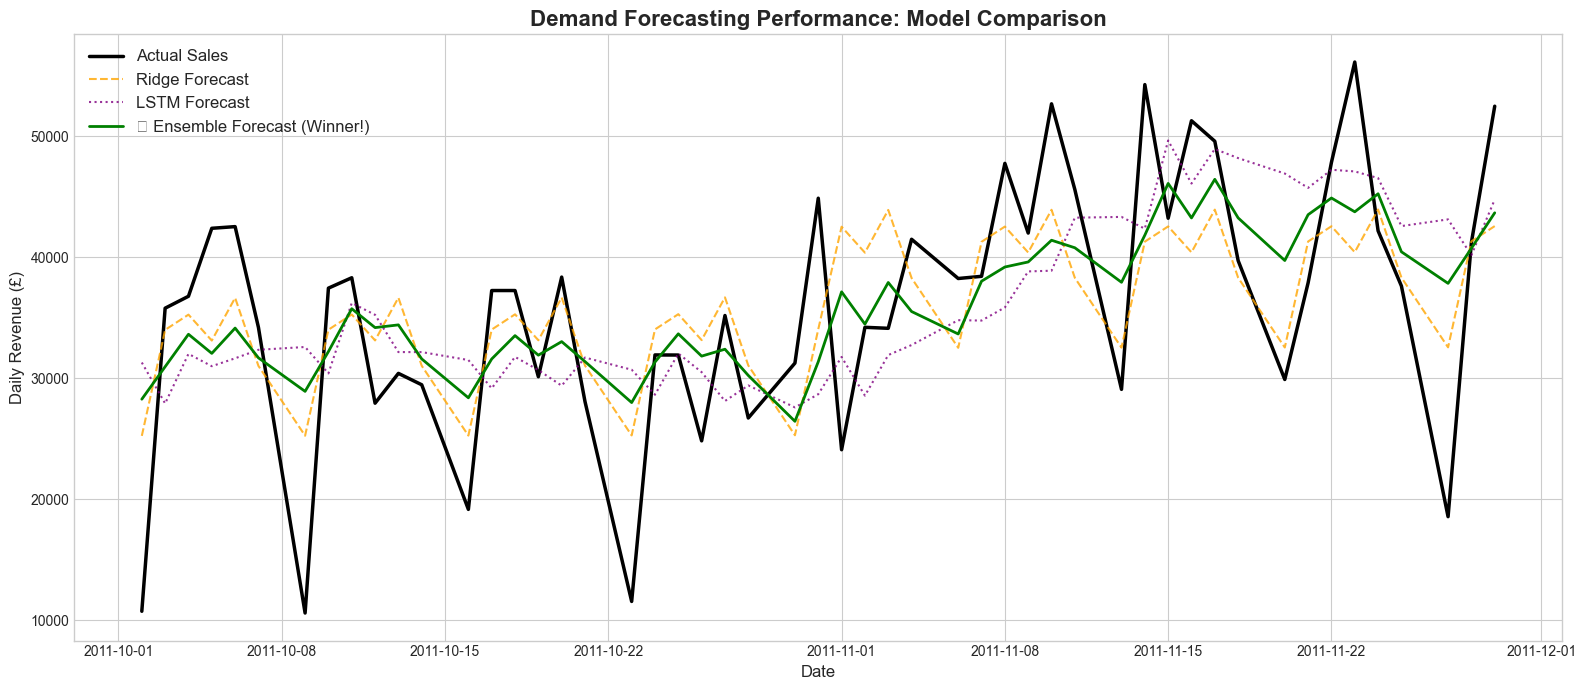

In [9]:
# ============================================
# PLOT MODEL COMPARISONS
# ============================================

plt.figure(figsize=(16, 7))
plt.plot(ensemble_df['Date'], ensemble_df['Actual'], color='black', linewidth=2.5, label='Actual Sales')
plt.plot(ensemble_df['Date'], ensemble_df['Ridge_Predicted'], color='orange', linestyle='--', alpha=0.8, label='Ridge Forecast')
plt.plot(ensemble_df['Date'], ensemble_df['LSTM_Predicted'], color='purple', linestyle=':', alpha=0.8, label='LSTM Forecast')
plt.plot(ensemble_df['Date'], ensemble_df['Ensemble_Predicted'], color='green', linewidth=2, label='💎 Ensemble Forecast (Winner!)')

plt.title('Demand Forecasting Performance: Model Comparison', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Daily Revenue (£)', fontsize=12)
plt.legend(fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "ensemble_comparison.png"), dpi=150, bbox_inches='tight')
plt.show()

In [10]:
# ============================================
# SAVE ENSEMBLE RESULTS
# ============================================

print("\n💾 SAVING ENSEMBLE RESULTS & METRICS...")
print("=" * 60)

# Save LSTM Model state dict (PyTorch recommended format)
lstm_model_path = os.path.join(project_root, "models", "forecasting", "lstm_model.pth")
torch.save(model.state_dict(), lstm_model_path)
print(f"   ✅ LSTM Model state dict saved: {lstm_model_path}")

# Save the ensemble forecast dataframe
ensemble_out_path = os.path.join(processed_dir, "ensemble_test_results.csv")
ensemble_df.to_csv(ensemble_out_path, index=False)
print(f"   ✅ Ensemble test results saved: {ensemble_out_path}")

# Save final metrics JSON (overwriting the old one to reflect ensemble values)
final_metrics = {
    "winner_model": best_model,
    "ridge_mape": float(round(ridge_mape, 2)),
    "lstm_mape": float(round(lstm_mape_test, 2)),
    "ensemble_mape": float(round(ens_mape, 2)),
    "target_mape": 12.0,
    "target_achieved": bool(ens_mape <= 12 or ridge_mape <= 12),
    "test_days": TEST_DAYS
}

metrics_json_path = os.path.join(processed_dir, "forecasting_metrics.json")
with open(metrics_json_path, 'w') as f:
    json.dump(final_metrics, f, indent=2)
print(f"   ✅ Master forecasting metrics saved: {metrics_json_path}")

print("\n🎉 STEP 8 COMPLETE: FORECASTING ENGINE FULLY BUILT!")


💾 SAVING ENSEMBLE RESULTS & METRICS...
   ✅ LSTM Model state dict saved: d:\Zudio Internship\Project 1\RetailPulse\models\forecasting\lstm_model.pth
   ✅ Ensemble test results saved: d:\Zudio Internship\Project 1\RetailPulse\data\processed\ensemble_test_results.csv
   ✅ Master forecasting metrics saved: d:\Zudio Internship\Project 1\RetailPulse\data\processed\forecasting_metrics.json

🎉 STEP 8 COMPLETE: FORECASTING ENGINE FULLY BUILT!
